# Data pre-processing and correlation analysis

In [32]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from pathlib import Path

# Ensure the 'data' directory exists
data_dir = Path.cwd() / "data"
data_dir.mkdir(parents=True, exist_ok=True)
mods = {"pandas": pd, "numpy": np, "matplotlib": sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "joblib": sys.modules.get("joblib"),
        "standardised_pipeline_utils": sys.modules.get("standardised_pipeline_utils")}
print(f"{'python':<28} {sys.version.split()[0]}")
for n, m in mods.items(): print(f"{n:<28} {getattr(m, '__version__', '(no __version__)') if m else 'not loaded'}")


python                       3.11.5
pandas                       2.3.2
numpy                        1.24.4
matplotlib                   3.7.2
scikit-learn                 1.7.2
joblib                       1.2.0
standardised_pipeline_utils  (no __version__)


#### Datasets Used:
 
CCLE genes expressions:
Proteomics:

In [4]:
transcriptomics = load(data_dir/"transcriptomics_filtered.joblib")
proteomics = load(data_dir / "proteomics_matched.joblib")
pearson = load(data_dir / "full_pearson100.joblib")

print(transcriptomics.shape)
print(proteomics.shape)

(369, 22614)
(369, 5113)


80/20 train-test split

In [5]:
# Take 10 samples for prot_test (reproducible)
n_test = 54
prot_test = proteomics.sample(n=min(n_test, len(proteomics)), random_state=42).copy()

# Keep the remaining samples as proteomics
proteomics = proteomics.drop(index=prot_test.index).copy()
transcriptomics_test = transcriptomics.loc[prot_test.index].copy()
transcriptomics = transcriptomics.drop(index=prot_test.index).copy()
print(proteomics.shape)
print(transcriptomics.shape)

(315, 5113)
(315, 22614)


### Correlations

In [16]:
# Find matched samples with samples and proteins with genes
transcriptomics_corr, proteomics_corr = standardised_pipeline_utils.match_proteins_samples(transcriptomics.T,
                                                                                           proteomics.T)

Number of common proteins:  4843
Number of common samples:  315


#### Pearson 

In [17]:
# Pearson correlation on 4843 features
pearson_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='pearson')
# Descriptive statistics on pearson correlation
pearson_correlations.describe()

count    4843.000000
mean        0.463328
std         0.217265
min        -0.157371
25%         0.309581
50%         0.471382
75%         0.629164
max         0.908735
dtype: float64

In [18]:
pe85_set = set(pearson_correlations[pearson_correlations > 0.85].index)
pe85 = list(pearson_correlations[pearson_correlations > 0.85].index)
pe85.sort(reverse=True)
print(len(pe85))


55


In [19]:
pe85

['VIM',
 'VIL1',
 'TRIP6',
 'TJP2',
 'TGM2',
 'ST14',
 'SPATS2L',
 'SLC16A3',
 'SIRPA',
 'SERPINB5',
 'SELENBP1',
 'S100A14',
 'RBM47',
 'PTK7',
 'PSMB8',
 'PDLIM4',
 'PDLIM1',
 'PAPSS2',
 'NT5E',
 'NNMT',
 'MYO1D',
 'MXRA7',
 'METTL7B',
 'MCAM',
 'MAP1B',
 'MAGEA4',
 'LCP1',
 'LAD1',
 'ITGB3',
 'ITGA2',
 'IGF2BP1',
 'IFI16',
 'HSPA2',
 'HCLS1',
 'GPX8',
 'GNG12',
 'GDA',
 'FHL2',
 'ERBB2',
 'EPCAM',
 'EGFR',
 'DPYSL3',
 'DCBLD2',
 'DAB2',
 'CORO1A',
 'CKAP4',
 'CDH2',
 'CDH1',
 'CDCP1',
 'CD44',
 'CA2',
 'BASP1',
 'ANPEP',
 'ALDH2',
 'ALDH1A3']

In [20]:
pearson_correlations['UCHL1']

0.8492427487449331

In [21]:
pe75 = set(pearson_correlations[pearson_correlations > 0.75].index)
len(pe75)

536

#### Spearman

In [22]:
# Spearman correlation on 4843 features

spearman_correlations = transcriptomics_corr.corrwith(proteomics_corr,
                                                      axis=1,
                                                      method='spearman')
# Descriptive statistics on spearman correlation
spearman_correlations.describe()

count    4843.000000
mean        0.445468
std         0.210686
min        -0.180386
25%         0.296545
50%         0.454568
75%         0.599395
max         0.890495
dtype: float64

In [23]:
sp75 = set(spearman_correlations[spearman_correlations > 0.75].index)
len(sp75)

401

In [24]:
sp85 = set(spearman_correlations[spearman_correlations > 0.85].index)
len(sp85)

40

### Linear regression baseline

In [10]:
# Cell A — compact helpers + incremental (LinearRegression) + test prep

# ---- helpers ----
def _metrics(y_true, y_pred):
    if len(y_true) < 2:
        return {'pearson': np.nan, 'spearman': np.nan, 'rmse': np.nan, 'mae': np.nan, 'r2': np.nan}
    try: r, _ = pearsonr(y_true, y_pred)
    except Exception: r = np.nan
    try: sp = spearmanr(y_true, y_pred).correlation
    except Exception: sp = np.nan
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    r2   = float(r2_score(y_true, y_pred))
    return {'pearson': float(r), 'spearman': float(sp), 'rmse': rmse, 'mae': mae, 'r2': r2}

def _stratify_bins(y, q=10):
    try: return pd.qcut(y, q=q, duplicates='drop')
    except Exception: return None

def _get_sorted_genes_by_corr(pearson_df, protein, use_abs=True, dropna=True):
    s = pearson_df.loc[protein]
    if dropna: s = s.dropna()
    return s.reindex(s.abs().sort_values(ascending=False).index) if use_abs else s.sort_values(ascending=False)

def _prepare_xy_multi(proteomics, transcriptomics, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics.columns]
    if not genes: raise ValueError("No genes present in transcriptomics for selection.")
    y = proteomics.loc[proteomics.index, protein].astype(float)
    X = transcriptomics.loc[proteomics.index, genes].astype(float)
    if transform == 'log1p': X = np.log1p(X)
    df = pd.concat([y.rename("__y__"), X], axis=1).dropna(axis=0)
    y = df.pop("__y__").values; X = df.values
    if X.shape[0] > 1:
        var = X.var(axis=0); keep = var > 0
        X = X[:, keep]; kept_genes = list(df.columns[keep])
    else:
        kept_genes = list(df.columns)
    return X, y, kept_genes

def _prepare_test_Xy(prot_test, transcriptomics_like, protein, genes, transform='log1p'):
    genes = [g for g in genes if g in transcriptomics_like.columns]
    if not genes: return None, None, [], pd.Index([])
    y_te = prot_test.loc[prot_test.index, protein].astype(float)
    X_te = transcriptomics_like.loc[prot_test.index, genes].astype(float)
    if transform == 'log1p': X_te = np.log1p(X_te)
    df_te = pd.concat([y_te.rename('__y__'), X_te], axis=1).dropna(axis=0)
    if df_te.empty: return None, None, [], pd.Index([])
    y_out = df_te.pop('__y__').values; X_out = df_te.values
    return X_out, y_out, list(df_te.columns), df_te.index

# ---- incremental forward selection (LinearRegression) ----
def run_incremental_until_mae(
    proteomics, transcriptomics, pearson_df, protein,
    mae_threshold=0.2,                  # fixed target (if set, schedule below ignored)
    threshold_start=None, threshold_end=None, threshold_schedule='geometric',
    max_features=200,
    min_improve_rel=0.0, min_improve_abs=0.0, patience=300,
    use_abs_corr=True, transform='log1p', test_size=0.2, random_state=42
):
    ranked = _get_sorted_genes_by_corr(pearson_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked.index if g in transcriptomics.columns]
    if not ranked: raise ValueError("No overlapping genes between pearson table and transcriptomics columns.")

    def _threshold_at(k):
        if mae_threshold is not None: return float(mae_threshold)
        if threshold_start is None and threshold_end is None: return np.inf
        if threshold_schedule == 'linear':
            if threshold_start is None or threshold_end is None: raise ValueError("linear schedule needs start and end")
            return float(threshold_start + (threshold_end - threshold_start) * ((k-1)/max(1,(max_features-1))))
        if threshold_start is None or threshold_end is None:
            return float(threshold_start * (0.95 ** (k-1))) if threshold_start is not None else np.inf
        factor = (threshold_end/threshold_start) ** (1.0/max(1,(max_features-1)))
        return float(threshold_start * (factor ** (k-1)))

    history, selected = [], []
    best_mae, no_improve = np.inf, 0
    final_model = None; final_metrics = None

    for g in ranked:
        cand = selected + [g]
        try:
            X, y, kept = _prepare_xy_multi(proteomics, transcriptomics, protein, cand, transform=transform)
        except ValueError:
            continue
        if X.shape[0] < 5: continue
        cand = [gg for gg in kept if gg in cand]
        if not cand: continue

        strat = _stratify_bins(y, q=10)
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=strat)
        model = LinearRegression().fit(X_tr, y_tr)
        m = _metrics(y_te, model.predict(X_te))

        k = len(cand); thr = _threshold_at(k)
        rel_ok = (m['mae'] <= best_mae * (1 - min_improve_rel)) if min_improve_rel > 0 else True
        abs_ok = (m['mae'] <= best_mae - min_improve_abs) if min_improve_abs > 0 else True
        improved = (m['mae'] < best_mae) and rel_ok and abs_ok

        if improved or best_mae == np.inf:
            selected, best_mae = cand, m['mae']
            no_improve = 0; final_model = model; final_metrics = m
            accepted = True
        else:
            accepted = False; no_improve += 1

        history.append({
            'k': k, 'threshold': thr, 'accepted': accepted,
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_train': len(y_tr), 'n_test': len(y_te),
            'genes_candidate': tuple(cand), 'genes_selected': tuple(selected)
        })

        if best_mae <= thr or len(selected) >= max_features or (patience is not None and no_improve >= patience):
            break

    history_df = pd.DataFrame(history)
    return {
        'protein': protein,
        'history_df': history_df,
        'final_genes': list(history_df.iloc[-1]['genes_selected']) if len(history_df) else [],
        'final_metrics': final_metrics,
        'model': final_model
    }


In [12]:
# top n enet

def run_elasticnet_topn(
    proteomics, transcriptomics, pearson_df, protein,
    top_n=200,
    use_abs_corr=True,             # rank by |corr|
    transform='log1p',             # ONLY applied to X
    test_size=0.2, random_state=42,
    alphas=(0.001),                   # None -> ENetCV default grid
    l1_ratios=(0.1, 0.5, 0.9),
    max_iter=10000, cv=5
):
    """
    Select the top-N genes by Pearson correlation (per protein) and fit ElasticNetCV.
    No scaling; only optional log1p on X. Returns metrics and best hyperparams.
    """
    ranked = _get_sorted_genes_by_corr(pearson_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked.index if g in transcriptomics.columns]
    if len(ranked) == 0:
        raise ValueError("No overlapping genes between pearson table and transcriptomics columns.")

    genes = ranked[:top_n]
    X, y, kept_genes = _prepare_xy_multi(proteomics, transcriptomics, protein, genes, transform=transform)
    if X.shape[0] < 5:
        raise ValueError("Too few usable samples after filtering.")

    # split & fit
    strat = _stratify_bins(y, q=10)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=strat
    )

    enet = ElasticNetCV(
        alphas=None if alphas is None else np.asarray(alphas, dtype=float),
        l1_ratio=np.array(l1_ratios, dtype=float) if l1_ratios is not None else (0.1, 0.5, 0.9),
        cv=cv, max_iter=max_iter, random_state=random_state
    )
    enet.fit(X_tr, y_tr)
    y_pred = enet.predict(X_te)
    m = _metrics(y_te, y_pred)

    return {
        'protein': protein,
        'genes': kept_genes,        # after constant-col drop
        'n_features': len(kept_genes),
        'metrics': m,
        'alpha_': float(enet.alpha_),
        'l1_ratio_': float(enet.l1_ratio_)
    }


In [13]:
# trial of two pe pipelines only one protein

PROTEIN = "VIL1"        # ← change this
MAE_THRESHOLD = 0.15     # stop condition for incremental
TOP_N = 25               # number of features for ElasticNetCV

# 1) Incremental LinearRegression until MAE <= threshold
res_inc = run_incremental_until_mae(
    proteomics, transcriptomics, pearson,
    protein=PROTEIN,
    mae_threshold=MAE_THRESHOLD,
    max_features=200,
    use_abs_corr=True,
    transform='log1p',
    test_size=0.2, random_state=42
)
print(f"[Incremental] protein={res_inc['protein']}")
display(res_inc['history_df'])
print("Final genes:", res_inc['final_genes'])
print("Final metrics:", res_inc['final_metrics'])

# 2) ElasticNetCV on top-N Pearson genes
res_enet = run_elasticnet_topn(
    proteomics, transcriptomics, pearson,
    protein=PROTEIN,
    top_n=TOP_N,
    use_abs_corr=True,
    transform='log1p',
    test_size=0.2, random_state=42,
    alphas=None, l1_ratios=(0.1, 0.5, 0.9), max_iter=1000, cv=5
)
print(f"\n[ElasticNetCV-Top{TOP_N}] protein={res_enet['protein']}")
print("Used genes (after constant drop):", res_enet['genes'])
print("n_features:", res_enet['n_features'])
print("alpha_:", res_enet['alpha_'], "l1_ratio_:", res_enet['l1_ratio_'])
print("metrics:", res_enet['metrics'])


[Incremental] protein=VIL1


,k,threshold,accepted,mae,rmse,r2,pearson,spearman,n_train,n_test,genes_candidate,genes_selected
0,1,0.15,True,0.564601,0.745932,0.788814,0.890743,0.394117,252,63,"(VIL1,)","(VIL1,)"
1,2,0.15,True,0.550498,0.731139,0.797108,0.895811,0.402079,252,63,"(VIL1, HNF4A)","(VIL1, HNF4A)"
2,3,0.15,False,0.594891,0.763278,0.778878,0.884631,0.400634,252,63,"(VIL1, HNF4A, EPS8L3)","(VIL1, HNF4A)"
3,3,0.15,True,0.541418,0.700371,0.813825,0.906292,0.433473,252,63,"(VIL1, HNF4A, CLRN3)","(VIL1, HNF4A, CLRN3)"
4,4,0.15,False,0.564684,0.709993,0.808674,0.902910,0.407738,252,63,"(VIL1, HNF4A, CLRN3, MIR194-2HG)","(VIL1, HNF4A, CLRN3)"
...,...,...,...,...,...,...,...,...,...,...,...,...
3199,195,0.15,False,0.697626,0.912596,0.683901,0.852719,0.499712,252,63,"(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA...","(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA..."
3200,195,0.15,False,0.824355,1.056539,0.576321,0.777958,0.663978,252,63,"(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA...","(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA..."
3201,195,0.15,False,0.629397,0.814392,0.748271,0.875386,0.588518,252,63,"(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA...","(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA..."
3202,195,0.15,False,0.503605,0.715931,0.805460,0.912702,0.657114,252,63,"(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA...","(VIL1, HNF4A, CLRN3, TM4SF5, MUC13, CDH17, PRA..."


Final genes: ['VIL1', 'HNF4A', 'CLRN3', 'TM4SF5', 'MUC13', 'CDH17', 'PRAP1', 'ZNF511-PRAP1', 'USH1C', 'CCL15', 'TRIM15', 'TSPAN8', 'BCAR3-AS1', 'LINC00543', 'FABP1', 'HNF1A-AS1', 'AC020656.2', 'REG4', 'PPP1R14D', 'AC016735.1', 'AL121992.3', 'TDGF1', 'LINC02313', 'APOBEC1', 'AC124067.4', 'AL163953.1', 'KLK1', 'IYD', 'PRR15L', 'AKR7L', 'GLYCTK', 'CALML4', 'FZD5', 'CTSE', 'LYZ', 'LINC01978', 'TMPRSS2', 'KCNQ1', 'LINC02747', 'TMEM45B', 'TOX3', 'HMGCS2', 'ADD3-AS1', 'FFAR4', 'CCNI2', 'ABCC6P1', 'AL024508.1', 'GMDS', 'AC020656.1', 'AC080037.2', 'SPINK1', 'B3GNT8', 'IL20RA', 'FAM3D', 'SHH', 'CAMSAP3', 'KCNE3', 'ANO9', 'AC005280.1', 'TTC7B', 'PIP5K1B', 'LINC01124', 'PRSS3', 'AP004608.1', 'AL118505.1', 'GJB1', 'IL17RE', 'PLEKHA6', 'RIPK3', 'KDM7A-DT', 'HHLA2', 'EPB41L4B', 'ARHGEF16', 'PLS1', 'AC131097.2', 'PHETA1', 'FGFR4', 'LGR5', 'ZSWIM5', 'LINC02418', 'SFTA2', 'DENND5A', 'AL121832.1', 'PLA2G2A', 'SLC26A3', 'TST', 'PLEKHG6', 'ADAP1', 'F10', 'IKBIP', 'SCPEP1', 'PIWIL2', 'LHFPL6', 'MAP3K3', 'PL

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(



[ElasticNetCV-Top25] protein=VIL1
Used genes (after constant drop): ['VIL1', 'HNF4A', 'EPS8L3', 'CLRN3', 'MIR194-2HG', 'HNF1A', 'TM4SF5', 'MOGAT3', 'MUC13', 'ANKS4B', 'CDH17', 'PRAP1', 'ZNF511-PRAP1', 'FOXA3', 'USH1C', 'ANKRD40CL', 'GPR35', 'CCL15', 'MYO1A', 'CDHR5', 'LGALS4', 'TRIM15', 'SLC39A5', 'PHGR1', 'BCL2L14']
n_features: 25
alpha_: 0.023941071253303112 l1_ratio_: 0.5
metrics: {'pearson': 0.9046521920272033, 'spearman': 0.5071044546850999, 'rmse': 0.7213781068053061, 'mae': 0.5421074936997227, 'r2': 0.8024887447598965}


In [ ]:
# Cell B — run training (incremental selection) + final testing on prot_test, end-to-end

# -------- config (edit here) --------
PROTEIN_LIST  = pe85          # list variable, e.g. pe85
MAE_THRESHOLD = 0.20
MAX_FEATURES  = 300
TEST_SIZE     = 0.20
RANDOM_STATE  = 42
USE_ABS_CORR  = True
TRANSFORM     = 'log1p'
# OUT_SUMMARY_CSV = 'incremental_summary.csv'
# OUT_TEST_CSV    = 'incremental_test_summary.csv'
# -----------------------------------

# ensure transcriptomics_test exists for prot_test
if 'transcriptomics_test' not in globals():
    transcriptomics_test = transcriptomics.loc[prot_test.index].copy()

# ---- TRAIN: incremental per protein -> summary_df ----
rows = []
for prot in PROTEIN_LIST:
    try:
        res = run_incremental_until_mae(
            proteomics, transcriptomics, pearson,
            protein=prot, mae_threshold=MAE_THRESHOLD,
            max_features=MAX_FEATURES, use_abs_corr=USE_ABS_CORR,
            transform=TRANSFORM, test_size=TEST_SIZE, random_state=RANDOM_STATE
        )
        hist = res['history_df']
        if isinstance(hist, pd.DataFrame) and len(hist):
            last = hist.iloc[-1]; m = res.get('final_metrics', {}) or {}
            rows.append({
                'protein': prot,
                'k_features': int(len(res.get('final_genes', []))),
                'mae': float(m.get('mae', np.nan)),
                'rmse': float(m.get('rmse', np.nan)),
                'r2': float(m.get('r2', np.nan)),
                'pearson': float(m.get('pearson', np.nan)),
                'spearman': float(m.get('spearman', np.nan)),
                'accepted_last_step': bool(last.get('accepted', True)),
                'genes': ';'.join(res.get('final_genes', [])),
                'status': 'ok'
            })
        else:
            rows.append({'protein': prot, 'status': 'no_valid_model'})
    except Exception as e:
        rows.append({'protein': prot, 'status': f'error: {e}'})

summary_df = pd.DataFrame(rows)
col_order = ['protein','k_features','mae','rmse','r2','pearson','spearman','accepted_last_step','genes','status']
for c in col_order:
    if c not in summary_df.columns: summary_df[c] = np.nan
summary_df['mae'] = pd.to_numeric(summary_df['mae'], errors='coerce')
summary_df = summary_df.reindex(columns=col_order).sort_values(by='mae', na_position='last').reset_index(drop=True)
summary_df.head(20)
# summary_df.to_csv(OUT_SUMMARY_CSV, index=False)

# ---- TEST: retrain on full TRAIN with chosen genes; evaluate on prot_test ----
test_rows = []
for _, row in summary_df.iterrows():
    prot = row['protein']; genes_str = row.get('genes', '')
    if pd.isna(prot) or not isinstance(genes_str, str) or not genes_str.strip():
        test_rows.append({'protein': prot, 'status': 'no_genes'}); continue
    genes = [g for g in genes_str.split(';') if g]
    try:
        X_tr, y_tr, kept = _prepare_xy_multi(proteomics, transcriptomics, prot, genes, transform=TRANSFORM)
        if X_tr is None or X_tr.shape[0] < 2 or not kept:
            test_rows.append({'protein': prot, 'status': 'no_train_data'}); continue
        model = LinearRegression().fit(X_tr, y_tr)

        X_te, y_te, used, kept_idx = _prepare_test_Xy(prot_test, transcriptomics_test, prot, kept, transform=TRANSFORM)
        if X_te is None or len(y_te) < 1:
            test_rows.append({'protein': prot, 'status': 'no_test_data'}); continue

        m = _metrics(y_te, model.predict(X_te))
        test_rows.append({
            'protein': prot, 'k_features': len(used),
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_test': int(len(y_te)), 'genes': ';'.join(used), 'status': 'ok'
        })
    except Exception as e:
        test_rows.append({'protein': prot, 'status': f'error: {e}'})

test_summary_df = pd.DataFrame(test_rows)
test_cols = ['protein','k_features','mae','rmse','r2','pearson','spearman','n_test','genes','status']
for c in test_cols:
    if c not in test_summary_df.columns: test_summary_df[c] = np.nan
test_summary_df['mae'] = pd.to_numeric(test_summary_df['mae'], errors='coerce')
test_summary_df = test_summary_df.reindex(columns=test_cols).sort_values(by='mae', na_position='last').reset_index(drop=True)

test_summary_df.head(20)
# test_summary_df.to_csv(OUT_TEST_CSV, index=False)


,protein,k_features,mae,rmse,r2,pearson,spearman,accepted_last_step,genes,status
0,PSMB8,220,0.124706,0.209237,0.962141,0.981162,0.979430,False,PSMB8;PSMB8-AS1;HLA-B;APOL6;TAP1;NLRC5;B2M;HLA...,ok
1,TJP2,234,0.133391,0.216524,0.967290,0.983542,0.987358,False,TJP2;TINAGL1;EPS8L2;KRT19;NIPAL1;CLDN4;CRB3;AN...,ok
2,PTK7,224,0.143278,0.274219,0.954757,0.977324,0.967629,False,PTK7;FBLN1;SIX4;EFNB3;NTF4;BCAM;S1PR5;IL17RD;T...,ok
3,LGALS1,221,0.144180,0.233083,0.976412,0.989391,0.985020,False,LGALS1;EMP3;ANXA5;HSD11B2;VIM-AS1;AXL;C2orf15;...,ok
4,CKAP4,212,0.155321,0.274020,0.941764,0.970701,0.967702,False,CKAP4;CFL2;GPX8;AC004687.1;BTK;KLHL6;NCF4;SPI1...,ok
5,ITGA2,236,0.161420,0.285611,0.965435,0.986038,0.989697,False,ITGA2;GPR39;LAMC2;F3;CDCP1;S100A16;ARL14;MYOF;...,ok
6,ERBB2,224,0.169904,0.292352,0.944370,0.972819,0.951845,False,ERBB2;KIAA1522;MIEN1;C6orf132;CTNND1;RHBDF1;GI...,ok
7,SERPINH1,234,0.170801,0.291154,0.931163,0.965773,0.958933,False,SERPINH1;GPX8;CAVIN1;AMOTL2;ARHGEF17;LAMB2;FST...,ok
8,PDLIM1,237,0.172567,0.284674,0.953706,0.978391,0.972525,False,PDLIM1;AC109322.1;IRF1;DLGAP1;VSIR;EFR3B;CERS1...,ok
9,DPYSL3,233,0.175256,0.260888,0.973673,0.987444,0.985824,False,DPYSL3;TMC6;CDH2;DPYSL2;KIAA0408;PTX3;VCAN;C8o...,ok


,protein,k_features,mae,rmse,r2,pearson,spearman,n_test,genes,status
0,GNG12,220,0.569090,0.692561,0.862229,0.948986,0.706957,24,GNG12;WAS;AC004687.1;TNFRSF12A;CD53;NCKAP1L;RH...,ok
1,MYO1D,227,0.570977,0.677041,0.640063,0.846887,0.732174,24,MYO1D;ERBB3;LAD1;BICDL2;C1orf210;FXYD3;EPCAM;O...,ok
2,PDLIM1,237,0.591239,0.806129,0.596407,0.793423,0.738261,24,PDLIM1;AC109322.1;IRF1;DLGAP1;VSIR;EFR3B;CERS1...,ok
3,DAB2,256,0.605314,0.759878,0.680804,0.845413,0.853043,24,DAB2;NNMT;MAGI2-AS3;SERPINE2;CDH2;CALU;DLC1;GN...,ok
4,TJP2,234,0.607464,0.745301,0.427841,0.723621,0.806087,24,TJP2;TINAGL1;EPS8L2;KRT19;NIPAL1;CLDN4;CRB3;AN...,ok
5,IGF2BP1,242,0.615758,0.742910,0.778815,0.889166,0.793043,24,IGF2BP1;AC091133.5;AC091133.3;P4HTM;ARID3A;TRI...,ok
6,MAP1B,220,0.620113,0.798232,0.722854,0.852167,0.857391,24,MAP1B;DCLK2;TMC6;DPYSL3;CHN1;GPR176;LARP6;SGCB...,ok
7,ERBB2,224,0.635267,0.876518,0.571745,0.829431,0.648696,24,ERBB2;KIAA1522;MIEN1;C6orf132;CTNND1;RHBDF1;GI...,ok
8,PSMB8,220,0.648330,0.887177,0.238507,0.672822,0.687826,24,PSMB8;PSMB8-AS1;HLA-B;APOL6;TAP1;NLRC5;B2M;HLA...,ok
9,RBM47,208,0.650777,0.813849,0.645652,0.849365,0.805217,24,RBM47;ELF3;MISP;EPS8L2;SPINT1-AS1;TMC4;FRK;KDF...,ok


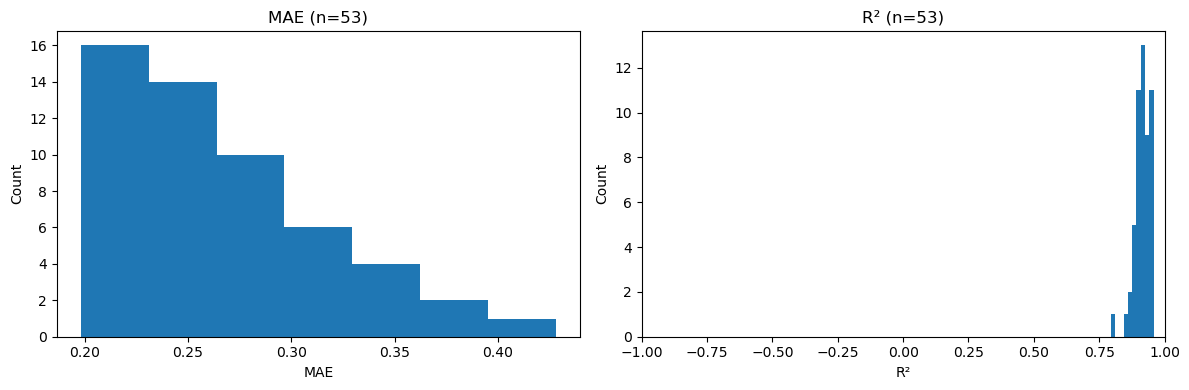

In [216]:
#histograms for MAE and R²
# Safely extract numeric series
mae = pd.to_numeric(summary_df.get('mae', pd.Series(dtype=float)), errors='coerce').dropna()
r2  = pd.to_numeric(summary_df.get('r2',  pd.Series(dtype=float)), errors='coerce').dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# MAE histogram
if len(mae):
    axes[0].hist(mae, bins='auto')
    axes[0].set_title(f"MAE (n={len(mae)})")
    axes[0].set_xlabel("MAE")
    axes[0].set_ylabel("Count")
else:
    axes[0].text(0.5, 0.5, "No MAE data", ha="center", va="center")
    axes[0].axis("off")

# R² histogram
if len(r2):
    axes[1].hist(r2, bins='auto')
    axes[1].set_title(f"R² (n={len(r2)})")
    axes[1].set_xlabel("R²")
    axes[1].set_ylabel("Count")
    axes[1].set_xlim(-1, 1)
else:
    axes[1].text(0.5, 0.5, "No R² data", ha="center", va="center")
    axes[1].axis("off")

plt.tight_layout()
plt.show()

### ElasticNet CROSSVAL

In [29]:
# enet incremental baseline function
def enet_incremental(
    proteomics, transcriptomics, pearson_df, protein,
    mae_threshold=0.5,                  # fixed target (if set, schedule below ignored)
    threshold_start=None, threshold_end=None, threshold_schedule='geometric',
    max_features=200,
    min_improve_rel=0.0, min_improve_abs=0.0, patience=300,
    use_abs_corr=True, transform='log1p', test_size=0.2, random_state=42,
    # ElasticNetCV hyperparam grid (5-fold CV each step)
    en_alphas=None,
    en_l1_ratios=None,
    en_max_iter=1000,
    en_tol=5e-3,
    n_jobs=None           # parallelism for ElasticNetCV
):
    """
    Incrementally adds genes (by abs Pearson rank) and, at each step, fits ElasticNetCV
    (5-fold) on the training split. NOTE: ElasticNetCV selects hyperparameters by MSE internally.
    """
    # defaults for grids
    if en_alphas is None:
        en_alphas = np.logspace(-4, 1, 4)   # ~0.0001..10 (4 values)
    if en_l1_ratios is None:
        en_l1_ratios = [0.1, 0.5, 0.9]

    ranked = _get_sorted_genes_by_corr(pearson_df, protein, use_abs=use_abs_corr)
    ranked = [g for g in ranked.index if g in transcriptomics.columns]
    if not ranked:
        raise ValueError("No overlapping genes between pearson table and transcriptomics columns.")

    def _threshold_at(k):
        if mae_threshold is not None: return float(mae_threshold)
        if threshold_start is None and threshold_end is None: return np.inf
        if threshold_schedule == 'linear':
            if threshold_start is None or threshold_end is None:
                raise ValueError("linear schedule needs start and end")
            return float(threshold_start + (threshold_end - threshold_start) * ((k-1)/max(1, (max_features-1))))
        if threshold_start is None or threshold_end is None:
            return float(threshold_start * (0.95 ** (k-1))) if threshold_start is not None else np.inf
        factor = (threshold_end/threshold_start) ** (1.0/max(1, (max_features-1)))
        return float(threshold_start * (factor ** (k-1)))

    history, selected = [], []
    best_mae, no_improve = np.inf, 0
    final_model = None; final_metrics = None

    # CV splitter for hyperparameter tuning (used inside ElasticNetCV)
    inner_cv = KFold(n_splits=5, shuffle=True, random_state=random_state)

    for g in ranked:
        cand = selected + [g]
        try:
            X, y, kept = _prepare_xy_multi(proteomics, transcriptomics, protein, cand, transform=transform)
        except ValueError:
            continue

        # need at least enough samples for both test split and CV
        min_needed = max(5, inner_cv.get_n_splits())
        if X.shape[0] < min_needed:
            continue

        # keep only genes that survived variance filter
        cand = [gg for gg in kept if gg in cand]
        if not cand:
            continue

        # hold-out split to evaluate each incremental step
        strat = _stratify_bins(y, q=10)
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, random_state=random_state, stratify=strat
        )

        # scale (fit on train only)
        scaler = StandardScaler(with_mean=True)
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)

        # ElasticNetCV (5-fold) — chooses alpha & l1_ratio by MSE
        enetcv = ElasticNetCV(
            l1_ratio=en_l1_ratios,
            alphas=en_alphas,
            cv=inner_cv,
            max_iter=en_max_iter,
            tol=en_tol,
            n_jobs=n_jobs
        )
        enetcv.fit(X_tr_s, y_tr)
        y_pred = enetcv.predict(X_te_s)
        m = _metrics(y_te, y_pred)

        # compute CV MSE at the chosen (alpha*, l1_ratio*)
        cv_mse_mean = np.nan
        try:
            alpha_star = enetcv.alpha_
            l1_star = enetcv.l1_ratio_
            mse_path = enetcv.mse_path_
            alphas_path = enetcv.alphas_

            if isinstance(alphas_path, list):  # multiple l1_ratios
                l1_list = np.array(enetcv.l1_ratio if hasattr(enetcv, "l1_ratio") else en_l1_ratios, dtype=float)
                idx_l1 = int(np.argmin(np.abs(l1_list - l1_star)))
                mean_mse_alpha = mse_path[idx_l1].mean(axis=-1)         # (n_alpha,)
                alpha_grid = alphas_path[idx_l1]                        # (n_alpha,)
                idx_alpha = int(np.argmin(np.abs(alpha_grid - alpha_star)))
                cv_mse_mean = float(mean_mse_alpha[idx_alpha])
            else:  # single l1_ratio
                mean_mse_alpha = mse_path.mean(axis=-1)                 # (n_alpha,)
                alpha_grid = alphas_path
                idx_alpha = int(np.argmin(np.abs(alpha_grid - alpha_star)))
                cv_mse_mean = float(mean_mse_alpha[idx_alpha])
        except Exception:
            cv_mse_mean = np.nan

        k = len(cand); thr = _threshold_at(k)
        rel_ok = (m['mae'] <= best_mae * (1 - min_improve_rel)) if min_improve_rel > 0 else True
        abs_ok = (m['mae'] <= best_mae - min_improve_abs) if min_improve_abs > 0 else True
        improved = (m['mae'] < best_mae) and rel_ok and abs_ok

        if improved or best_mae == np.inf:
            selected, best_mae = cand, m['mae']
            no_improve = 0
            # return a fitted pipeline (scaler + fitted ENetCV)
            from sklearn.pipeline import Pipeline
            final_model = Pipeline([('scaler', scaler), ('model', enetcv)])
            final_metrics = m
            accepted = True
        else:
            accepted = False
            no_improve += 1

        history.append({
            'k': k, 'threshold': thr, 'accepted': accepted,
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_train': len(y_tr), 'n_test': len(y_te),
            'genes_candidate': tuple(cand), 'genes_selected': tuple(selected),
            # CV diagnostics from ElasticNetCV
            'cv_mse_mean': cv_mse_mean,
            'best_alpha': float(enetcv.alpha_),
            'best_l1_ratio': float(enetcv.l1_ratio_)
        })

        if best_mae <= thr or len(selected) >= max_features or (patience is not None and no_improve >= patience):
            break

    history_df = pd.DataFrame(history)
    return {
        'protein': protein,
        'history_df': history_df,
        'final_genes': list(history_df.iloc[-1]['genes_selected']) if len(history_df) else [],
        'final_metrics': final_metrics,
        'model': final_model
    }



In [33]:
# -------- config (edit here) --------
PROTEIN_LIST  = pe85          # list variable, e.g. pe85
MAE_THRESHOLD = 0.20
MAX_FEATURES  = 300
TEST_SIZE     = 0.20
RANDOM_STATE  = 42
USE_ABS_CORR  = True
TRANSFORM     = 'log1p'
# OUT_SUMMARY_CSV = 'incremental_summary.csv'
# OUT_TEST_CSV    = 'incremental_test_summary.csv'
# -----------------------------------

# ensure transcriptomics_test exists for prot_test
if 'transcriptomics_test' not in globals():
    transcriptomics_test = transcriptomics.loc[prot_test.index].copy()

# ---- TRAIN: incremental per protein -> summary_df ----
rows = []
for prot in PROTEIN_LIST:
    try:
        res = enet_incremental(
            proteomics, transcriptomics, pearson,
            protein=prot, mae_threshold=MAE_THRESHOLD,
            max_features=MAX_FEATURES, use_abs_corr=USE_ABS_CORR,
            transform=TRANSFORM, test_size=TEST_SIZE, random_state=RANDOM_STATE
        )
        hist = res['history_df']
        if isinstance(hist, pd.DataFrame) and len(hist):
            last = hist.iloc[-1]; m = res.get('final_metrics', {}) or {}
            rows.append({
                'protein': prot,
                'k_features': int(len(res.get('final_genes', []))),
                'mae': float(m.get('mae', np.nan)),
                'rmse': float(m.get('rmse', np.nan)),
                'r2': float(m.get('r2', np.nan)),
                'pearson': float(m.get('pearson', np.nan)),
                'spearman': float(m.get('spearman', np.nan)),
                'accepted_last_step': bool(last.get('accepted', True)),
                'genes': ';'.join(res.get('final_genes', [])),
                'status': 'ok'
            })
        else:
            rows.append({'protein': prot, 'status': 'no_valid_model'})
    except Exception as e:
        rows.append({'protein': prot, 'status': f'error: {e}'})

summary_df = pd.DataFrame(rows)
col_order = ['protein','k_features','mae','rmse','r2','pearson','spearman','accepted_last_step','genes','status']
for c in col_order:
    if c not in summary_df.columns: summary_df[c] = np.nan
summary_df['mae'] = pd.to_numeric(summary_df['mae'], errors='coerce')
summary_df = summary_df.reindex(columns=col_order).sort_values(by='mae', na_position='last').reset_index(drop=True)
summary_df.head(20)
# summary_df.to_csv(OUT_SUMMARY_CSV, index=False)

# ---- TEST: retrain on full TRAIN with chosen genes; evaluate on prot_test ----
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.model_selection import KFold

test_rows = []
for _, row in summary_df.iterrows():
    prot = row['protein']; genes_str = row.get('genes', '')
    if pd.isna(prot) or not isinstance(genes_str, str) or not genes_str.strip():
        test_rows.append({'protein': prot, 'status': 'no_genes'}); continue
    genes = [g for g in genes_str.split(';') if g]
    try:
        X_tr, y_tr, kept = _prepare_xy_multi(proteomics, transcriptomics, prot, genes, transform=TRANSFORM)
        if X_tr is None or X_tr.shape[0] < 2 or not kept:
            test_rows.append({'protein': prot, 'status': 'no_train_data'}); continue

        # scale train -> fit ENetCV on the full TRAIN (same grid as training phase)
        scaler = StandardScaler(with_mean=True)
        X_tr_s = scaler.fit_transform(X_tr)

        inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        enetcv_full = ElasticNetCV(
            l1_ratio=[0.1, 0.5, 0.9],                    # keep consistent with enet_incremental
            alphas=np.logspace(-4, 1, 4),
            cv=inner_cv,
            max_iter=1000,
            tol=5e-3,
            n_jobs=None
        ).fit(X_tr_s, y_tr)

        # prepare TEST with the same genes and scaler
        X_te, y_te, used, kept_idx = _prepare_test_Xy(prot_test, transcriptomics_test, prot, kept, transform=TRANSFORM)
        if X_te is None or len(y_te) < 1:
            test_rows.append({'protein': prot, 'status': 'no_test_data'}); continue

        X_te_s = scaler.transform(X_te)
        y_pred = enetcv_full.predict(X_te_s)
        m = _metrics(y_te, y_pred)

        test_rows.append({
            'protein': prot, 'k_features': len(used),
            'mae': m['mae'], 'rmse': m['rmse'], 'r2': m['r2'],
            'pearson': m['pearson'], 'spearman': m['spearman'],
            'n_test': int(len(y_te)), 'genes': ';'.join(used), 'status': 'ok'
        })
    except Exception as e:
        test_rows.append({'protein': prot, 'status': f'error: {e}'})

test_summary_df = pd.DataFrame(test_rows)
test_cols = ['protein','k_features','mae','rmse','r2','pearson','spearman','n_test','genes','status']
for c in test_cols:
    if c not in test_summary_df.columns: test_summary_df[c] = np.nan
test_summary_df['mae'] = pd.to_numeric(test_summary_df['mae'], errors='coerce')
test_summary_df = test_summary_df.reindex(columns=test_cols).sort_values(by='mae', na_position='last').reset_index(drop=True)

test_summary_df.head(20)
# test_summary_df.to_csv(OUT_TEST_CSV, index=False)


KeyboardInterrupt: 